# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import MADOSDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 2803


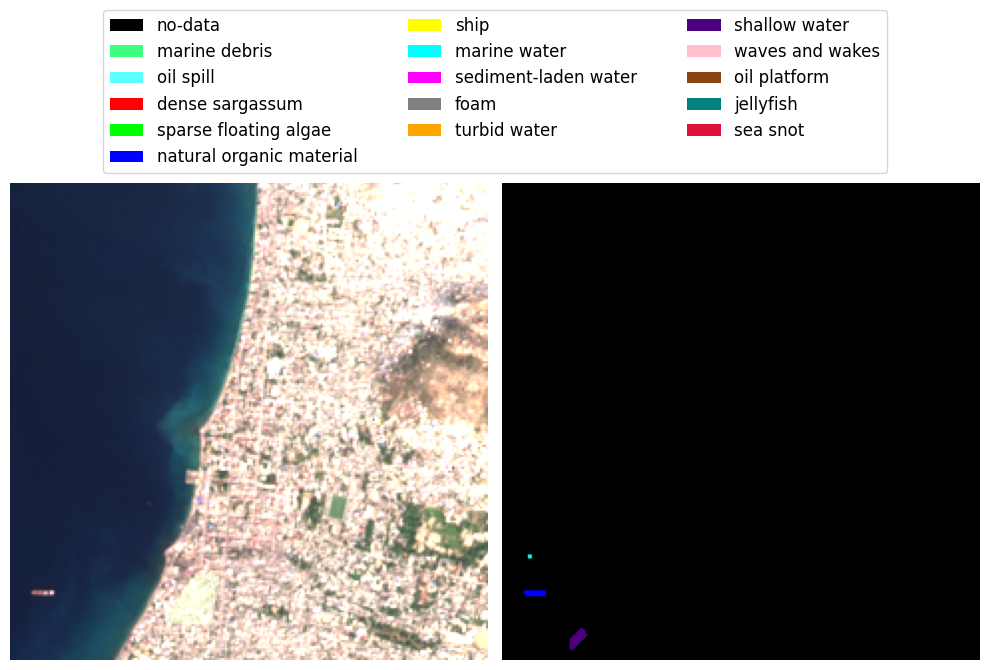

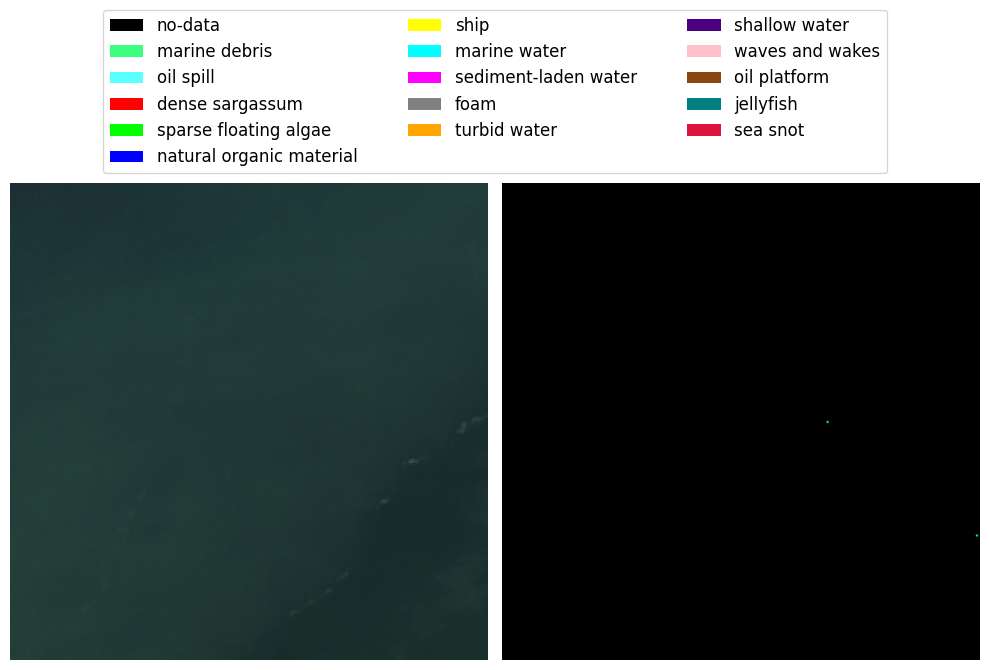

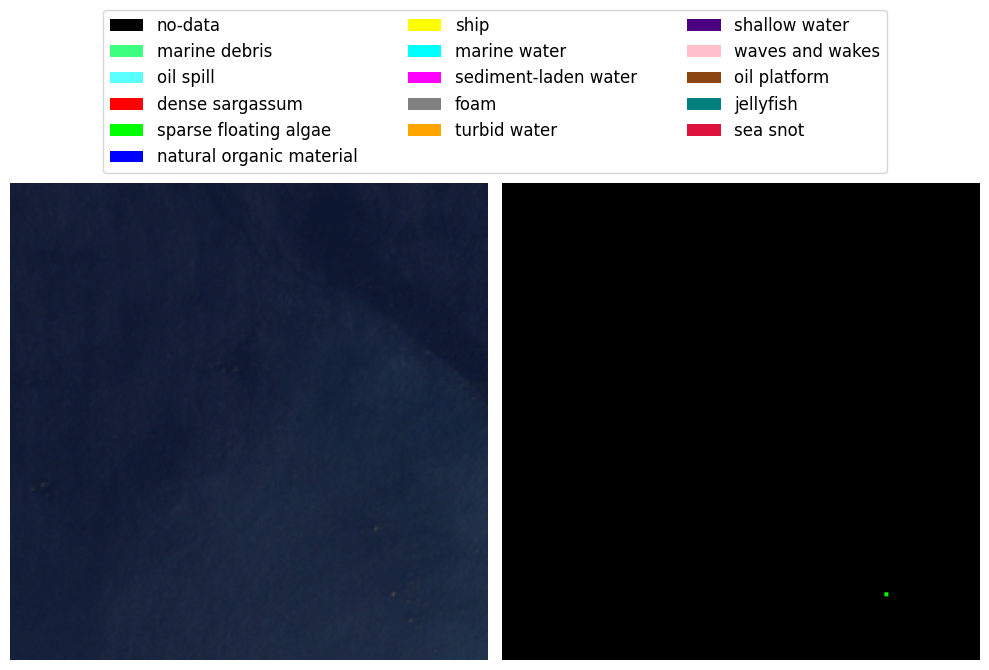

In [ ]:
dataset_config = {
    "data_dir": "./data/mados/",
}
dataset = MADOSDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(2);
dataset.show_image(2000);
dataset.show_image(400);

In [56]:
dataset.data_distribution_table()

,Number of pixels
no-data,159971645.0
marine debris,4696.0
oil spill,4308.0
dense sargassum,4972.0
sparse floating algae,1454.0
natural organic material,13222.0
ship,234568.0
marine water,496702.0
sediment-laden water,376061.0
foam,1225.0


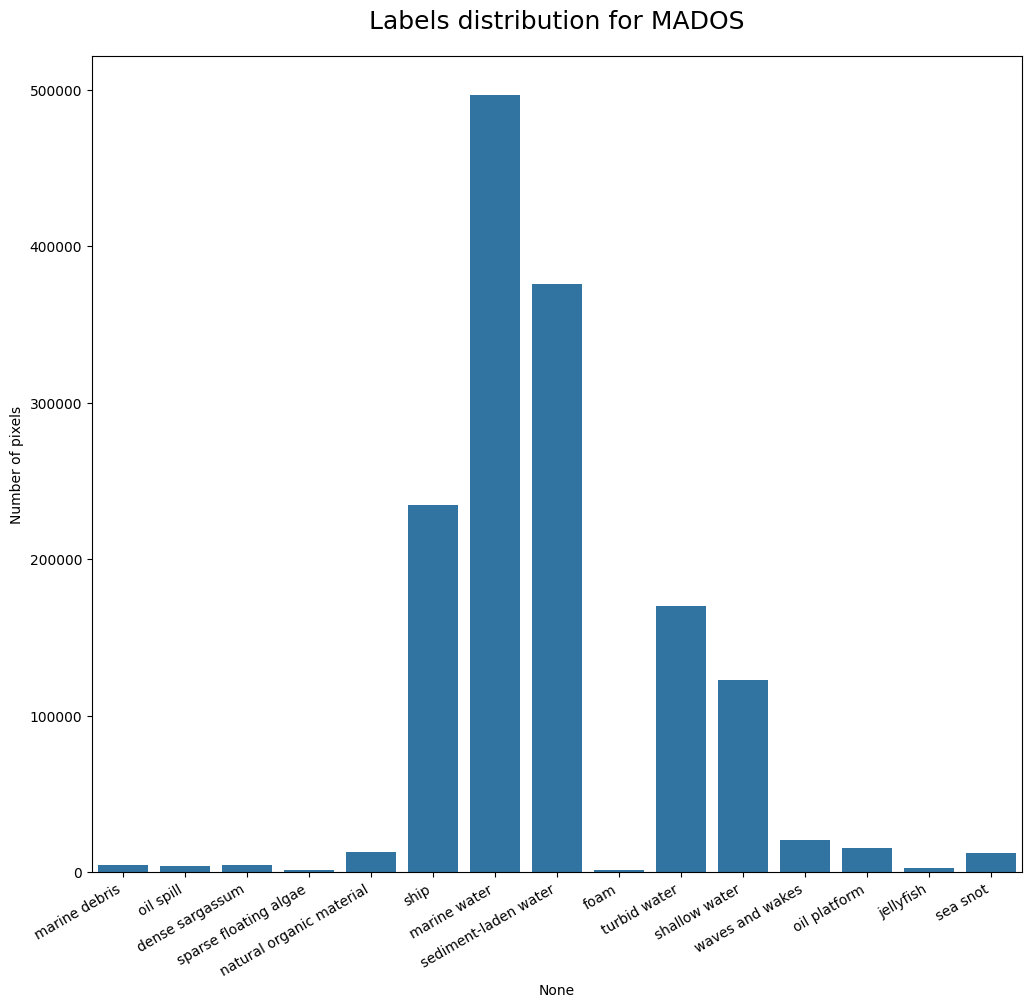

In [57]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/mados/",
    "csv_file": "./data/mados/splits/train_X.txt",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = MADOSDataset(train_dataset_config)
len(train_dataset)

1433

## Create the model

In [ ]:
epochs = 20
model_directory = "./data/experiments/mados"
model_config = {
    "num_classes": 16, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [71]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2026-04-20 08:33:21,610 INFO Starting training.
training: 100%|██████████| 90/90 [00:16<00:00,  5.35it/s]
2026-04-20 08:33:38,476 INFO epoch: 1, time: 17, loss:  0.84239
testing on train set: 100%|██████████| 90/90 [00:09<00:00,  9.79it/s]
2026-04-20 08:33:49,038 INFO IOU:0.42917754093699967, IOU mean:0.04680278063914273, IOU per Class:[7.44439557e-01 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 3.03432413e-03 0.00000000e+00 8.15230422e-04 0.00000000e+00
 4.89998439e-05 0.00000000e+00 0.00000000e+00 5.06378713e-04]
training: 100%|██████████| 90/90 [00:16<00:00,  5.30it/s]
2026-04-20 08:34:06,025 INFO epoch: 2, time: 17, loss:  0.73590
testing on train set: 100%|██████████| 90/90 [00:09<00:00,  9.87it/s]
2026-04-20 08:34:15,176 INFO IOU:0.8929056802652582, IOU mean:0.05627335709155538, IOU per Class:[0.90037371 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.       

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/mados/",
    "csv_file": "./data/mados/splits/val_X.txt",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = MADOSDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/mados/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

642


2026-04-20 08:46:50,596 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/mados/checkpoint.pth.tar
2026-04-20 08:46:51,074 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/mados/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 161/161 [00:05<00:00, 31.35it/s]


[{'IOU': 0.9806997064328281,
  'IOU mean': 0.06183970680117978,
  'IOU per Class': array([0.98943531, 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ,
         0.        ])}]

## Predictions

2026-04-20 08:48:30,162 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/mados/checkpoint.pth.tar
2026-04-20 08:48:30,558 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/mados/checkpoint.pth.tar at epoch 21


728


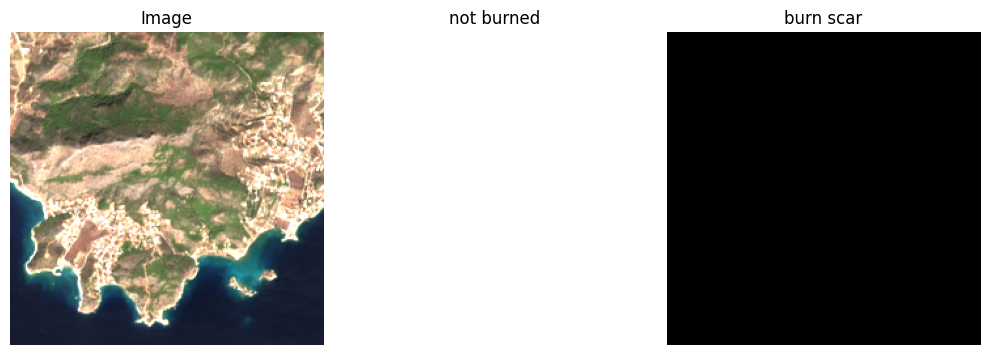

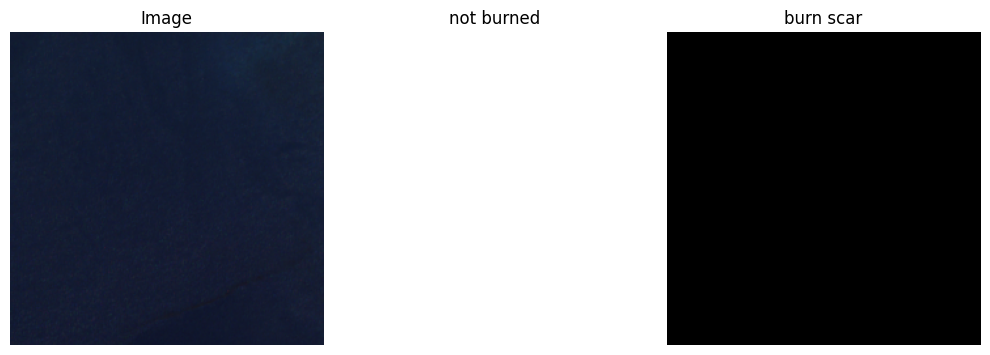

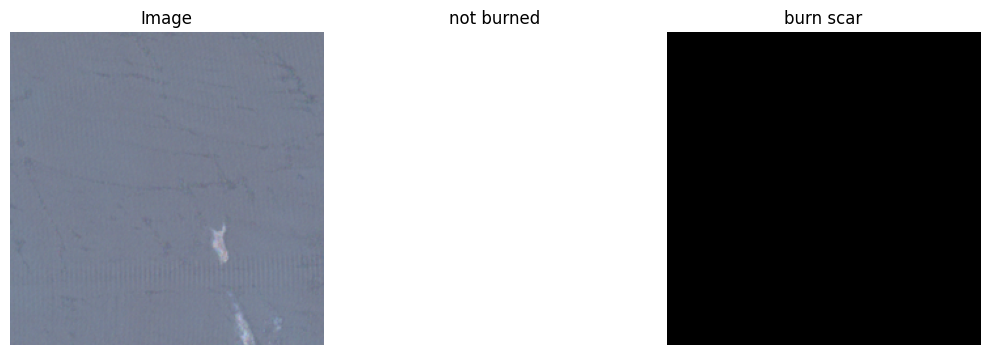

In [ ]:
model_path = "./data/experiments/mados/checkpoint.pth.tar"
labels = ["not burned","burn scar"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "./data/mados/",
    "csv_file": "./data/mados/splits/test_X.txt"
}
test_dataset = MADOSDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_masks(image, labels, transform)